# Final Assignment: Create Visualizations using Matplotlib, Seaborn & Folium



In [1]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline
sns.set_theme(style="whitegrid")


## 1. Create and inspect a sample dataset

In [3]:
# Reproducible example dataset
data = {
    "City": ["Ahmedabad", "Bengaluru", "Mumbai", "Delhi", "Chennai", "Hyderabad", "Pune", "Kolkata"],
    "Region": ["West", "South", "West", "North", "South", "South", "West", "East"],
    "Population_Millions": [8.4, 12.3, 20.0, 19.0, 11.5, 10.5, 7.4, 14.8],
    "Average_Temperature_C": [29, 27, 28, 25, 30, 28, 26, 29],
    "Annual_Rainfall_mm": [800, 970, 2200, 800, 1400, 900, 720, 1800],
    "Literacy_Percent": [89, 89, 90, 88, 90, 83, 91, 87],
}
df = pd.DataFrame(data)
display(df)
print("\nDataset shape:", df.shape)
print("\nSummary statistics:")

# Select numeric columns manually to ensure backward compatibility with older pandas versions
numeric_df = df.select_dtypes(include="number")
display(numeric_df.describe().round(2))

,City,Region,Population_Millions,Average_Temperature_C,Annual_Rainfall_mm,Literacy_Percent
0,Ahmedabad,West,8.4,29,800,89
1,Bengaluru,South,12.3,27,970,89
2,Mumbai,West,20.0,28,2200,90
3,Delhi,North,19.0,25,800,88
4,Chennai,South,11.5,30,1400,90
5,Hyderabad,South,10.5,28,900,83
6,Pune,West,7.4,26,720,91
7,Kolkata,East,14.8,29,1800,87



Dataset shape: (8, 6)

Summary statistics:


,Population_Millions,Average_Temperature_C,Annual_Rainfall_mm,Literacy_Percent
count,8.00,8.00,8.00,8.00
mean,12.99,27.75,1198.75,88.38
std,4.63,1.67,546.85,2.50
min,7.40,25.00,720.00,83.00
25%,9.98,26.75,800.00,87.75
50%,11.90,28.00,935.00,89.00
75%,15.85,29.00,1500.00,90.00
max,20.00,30.00,2200.00,91.00


## 2. Matplotlib: bar chart of population by city

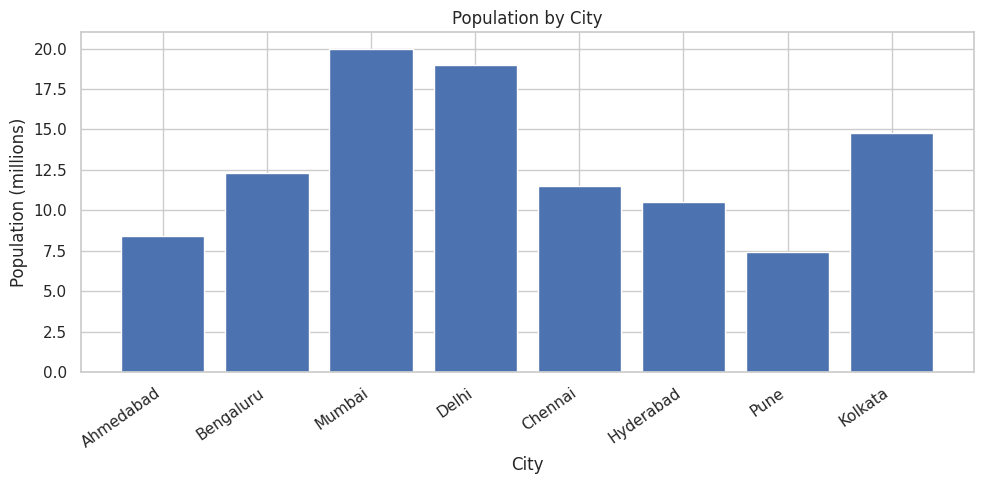

In [4]:
plt.figure(figsize=(10, 5))
plt.bar(df["City"], df["Population_Millions"])
plt.title("Population by City")
plt.xlabel("City")
plt.ylabel("Population (millions)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()


## 3. Matplotlib: line chart of temperature by city

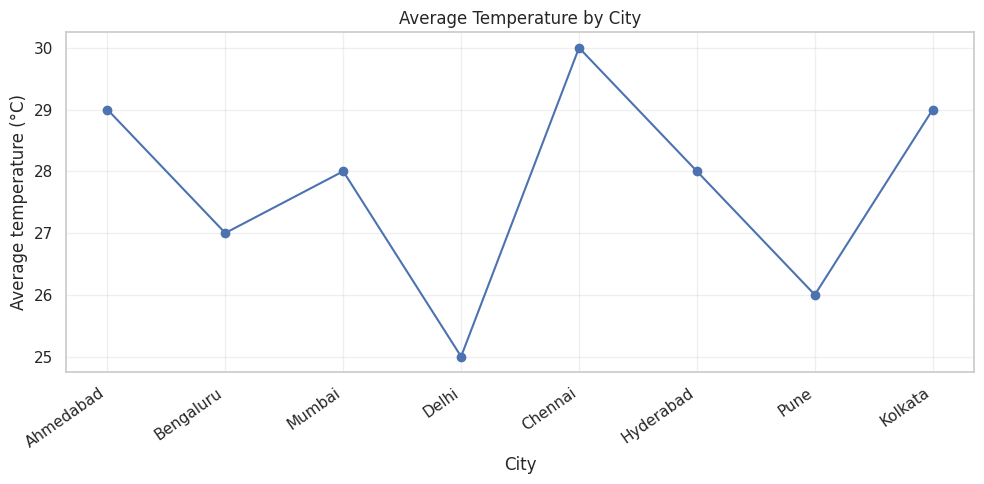

In [5]:
plt.figure(figsize=(10, 5))
plt.plot(df["City"], df["Average_Temperature_C"], marker="o")
plt.title("Average Temperature by City")
plt.xlabel("City")
plt.ylabel("Average temperature (°C)")
plt.xticks(rotation=35, ha="right")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## 4. Seaborn: scatter plot of population and rainfall

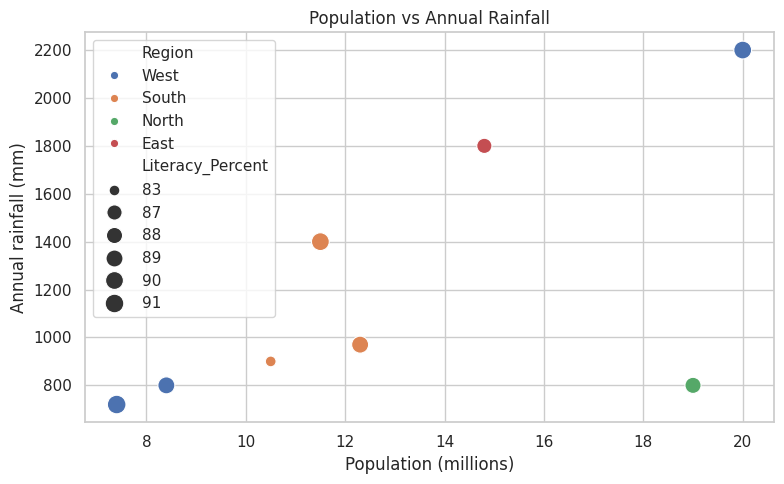

In [6]:
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x="Population_Millions",
    y="Annual_Rainfall_mm",
    hue="Region",
    size="Literacy_Percent",
    sizes=(60, 180)
)
plt.title("Population vs Annual Rainfall")
plt.xlabel("Population (millions)")
plt.ylabel("Annual rainfall (mm)")
plt.tight_layout()
plt.show()


## 5. Seaborn: box plot of temperature by region

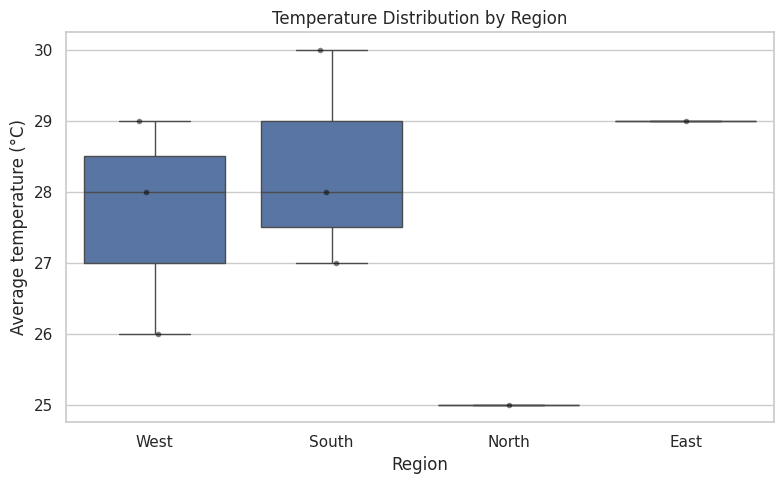

In [7]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="Region", y="Average_Temperature_C")
sns.stripplot(data=df, x="Region", y="Average_Temperature_C", color="black", alpha=0.5, size=4)
plt.title("Temperature Distribution by Region")
plt.xlabel("Region")
plt.ylabel("Average temperature (°C)")
plt.tight_layout()
plt.show()


## 6. Seaborn: correlation heatmap

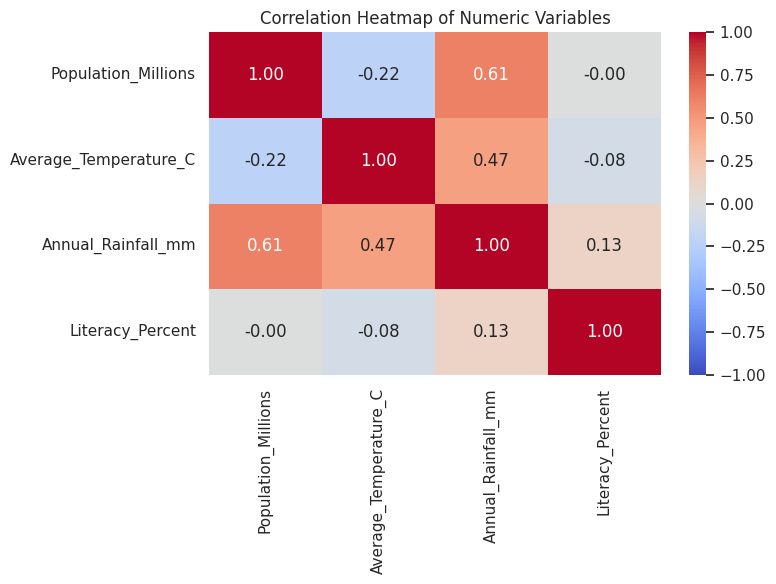

In [8]:
numeric_df = df.select_dtypes(include="number")
plt.figure(figsize=(8, 6))
sns.heatmap(numeric_df.corr(), annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Correlation Heatmap of Numeric Variables")
plt.tight_layout()
plt.show()


## 7. Folium: interactive map of selected Indian cities

Folium creates an interactive map. The coordinates below are approximate city-center locations. The map is centered on India, with a marker for each city and a popup showing selected data.

If Folium is not installed in your environment, run `!pip install folium` in a separate notebook cell and then rerun this section.


In [9]:
import folium

city_coordinates = {
    "Ahmedabad": (23.0225, 72.5714),
    "Bengaluru": (12.9716, 77.5946),
    "Mumbai": (19.0760, 72.8777),
    "Delhi": (28.6139, 77.2090),
    "Chennai": (13.0827, 80.2707),
    "Hyderabad": (17.3850, 78.4867),
    "Pune": (18.5204, 73.8567),
    "Kolkata": (22.5726, 88.3639),
}

india_map = folium.Map(location=[22.5, 79.0], zoom_start=5, tiles="OpenStreetMap")

for _, row in df.iterrows():
    lat, lon = city_coordinates[row["City"]]
    popup_text = (
        f"<b>{row['City']}</b><br>"
        f"Population: {row['Population_Millions']} million<br>"
        f"Temperature: {row['Average_Temperature_C']} °C<br>"
        f"Rainfall: {row['Annual_Rainfall_mm']} mm"
    )
    folium.CircleMarker(
        location=[lat, lon],
        radius=max(5, row["Population_Millions"] / 2),
        popup=folium.Popup(popup_text, max_width=250),
        tooltip=row["City"],
        fill=True
    ).add_to(india_map)

india_map


## 8. Save the interactive map as an HTML file

The HTML file can be opened in a browser. This cell saves the map alongside the notebook.


In [11]:
map_file = "indian_cities_interactive_map.html"
india_map.save(map_file)
print(f"Interactive map saved to: {map_file}")


Interactive map saved to: indian_cities_interactive_map.html
